# Credit Risk Score Generation, Model Comparison & Fairness Analysis

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

---

## Notebook Objectives

This notebook represents the final stage of the Credit Risk Scoring System. It consolidates the outputs generated by all previous notebooks and transforms the predictive models into an interpretable credit risk scoring framework suitable for lending decisions.

The objectives of this notebook are to:

- Compare the performance of all trained machine learning models.
- Automatically identify the best-performing classifier.
- Load the best saved model.
- Generate applicant-level default probabilities.
- Convert probabilities into standardized credit risk scores (300–900).
- Categorize applicants into interpretable risk bands.
- Evaluate fairness and stability across demographic groups.
- Produce the final credit risk scoring dataset.

This notebook bridges predictive analytics with business decision-making by translating machine learning outputs into practical credit scores that can assist loan officers during the loan approval process.

# Import Required Libraries

The following libraries are used throughout this notebook for loading trained models, comparing model performance, generating credit scores, visualizing results, and evaluating fairness across applicant groups.

In [16]:
# ============================================================
# Import Required Libraries
# ============================================================

from pathlib import Path
import joblib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Define Project Directories

To maintain consistency across the project, the locations of the processed datasets, saved models, and result files are defined.

Using directory variables improves portability and simplifies file management.

In [17]:
# ============================================================
# Project Directories
# ============================================================

DATA_DIR = Path("../data/processed")

MODEL_DIR = Path("../models")

RESULT_DIR = Path("../results")

print("Directories Loaded Successfully")

Directories Loaded Successfully


# Load Model Performance Results

The performance metrics of all machine learning models developed throughout this project are loaded.

These metrics will be used to compare the models and identify the best-performing classifier.

In [18]:
# ============================================================
# Load Model Results
# ============================================================

results = pd.read_csv(
    RESULT_DIR / "model_results.csv"
)

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,Logistic Regression,0.919581,0.552486,0.020141,0.038865,0.758259,81,4865,100,56457
1,Decision Tree Classifier,0.917971,0.142857,0.003223,0.006303,0.686772,96,4949,16,56442
2,K-Nearest Neighbors,0.914329,0.244966,0.029406,0.052509,0.591036,450,4819,146,56088
3,Gaussian Naïve Bayes,0.875697,0.119966,0.085196,0.099635,0.626254,3103,4542,423,53435
4,Random Forest,0.919142,0.100000,0.000201,0.000402,0.729338,9,4964,1,56529
5,XGBoost,0.745264,0.181184,0.612487,0.279645,0.752078,13743,1924,3041,42795
6,LightGBM,0.720485,0.173555,0.654582,0.274366,0.754543,15476,1715,3250,41062


# Model Performance Ranking

The machine learning models are ranked according to their ROC-AUC score.

ROC-AUC is selected as the primary evaluation metric because it measures the ability of the classifier to distinguish between default and non-default applicants across all possible decision thresholds.

A higher ROC-AUC indicates better discriminative performance.

In [19]:
# ============================================================
# Rank Models
# ============================================================

ranking = results.sort_values(
    by="ROC AUC",
    ascending=False
).reset_index(drop=True)

ranking

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,Logistic Regression,0.919581,0.552486,0.020141,0.038865,0.758259,81,4865,100,56457
1,LightGBM,0.720485,0.173555,0.654582,0.274366,0.754543,15476,1715,3250,41062
2,XGBoost,0.745264,0.181184,0.612487,0.279645,0.752078,13743,1924,3041,42795
3,Random Forest,0.919142,0.100000,0.000201,0.000402,0.729338,9,4964,1,56529
4,Decision Tree Classifier,0.917971,0.142857,0.003223,0.006303,0.686772,96,4949,16,56442
5,Gaussian Naïve Bayes,0.875697,0.119966,0.085196,0.099635,0.626254,3103,4542,423,53435
6,K-Nearest Neighbors,0.914329,0.244966,0.029406,0.052509,0.591036,450,4819,146,56088


# Visual Comparison of Model Performance

A bar chart is used to compare the ROC-AUC scores of all machine learning models.

This visualization provides a quick overview of the relative predictive performance of each classifier.

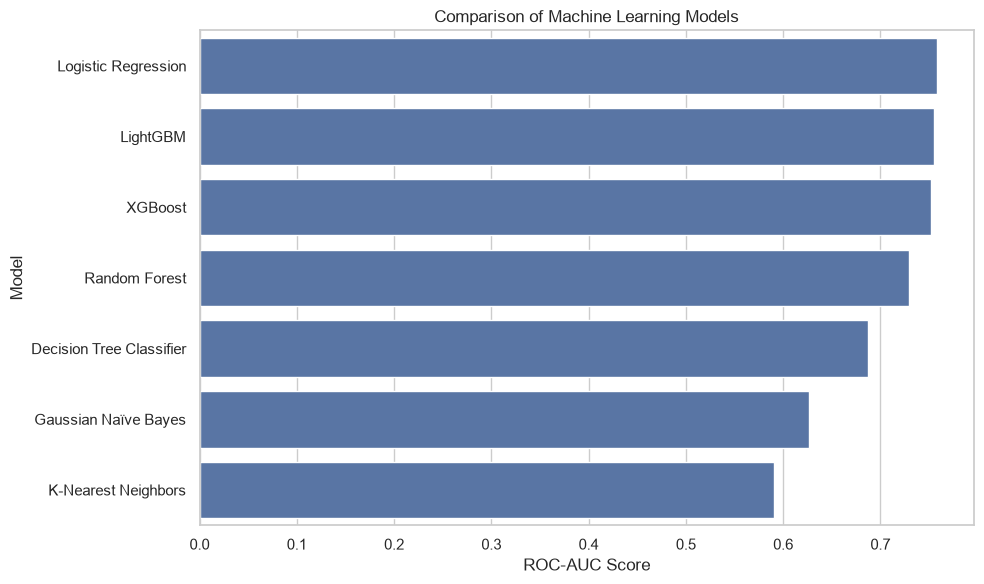

In [20]:
# ============================================================
# ROC-AUC Comparison
# ============================================================

plt.figure(figsize=(10,6))

sns.barplot(
    data=ranking,
    x="ROC AUC",
    y="Model"
)

plt.title("Comparison of Machine Learning Models")

plt.xlabel("ROC-AUC Score")

plt.ylabel("Model")

plt.tight_layout()

plt.show()

# Identify the Best Performing Model

The classifier with the highest ROC-AUC score is selected as the final credit risk prediction model.

This model will be used to estimate applicant default probabilities and generate standardized credit risk scores.

In [21]:
# ============================================================
# Best Model
# ============================================================

best_model_name = ranking.iloc[0]["Model"]

best_auc = ranking.iloc[0]["ROC AUC"]

print(f"Best Model : {best_model_name}")

print(f"ROC-AUC    : {best_auc:.4f}")

Best Model : Logistic Regression
ROC-AUC    : 0.7583


# Load the Best Performing Model

The best-performing machine learning model identified in the previous section is loaded from the saved model directory.

Instead of manually specifying the model, the notebook automatically selects the classifier with the highest ROC-AUC score recorded in the model comparison results. This ensures that the credit risk scoring system always uses the most effective predictive model.

In [22]:
# ============================================================
# Load Best Saved Model
# ============================================================

model_files = {

    "Logistic Regression": "logistic_regression_model.pkl",

    "Decision Tree": "decision_tree_model.pkl",

    "K-Nearest Neighbors": "knn_model.pkl",

    "Gaussian Naïve Bayes": "gaussian_nb_model.pkl",

    "Random Forest": "random_forest_model.pkl",

    "XGBoost": "xgboost_model.pkl",

    "LightGBM": "lightgbm_model.pkl"

}

best_model = joblib.load(
    MODEL_DIR / model_files[best_model_name]
)

print(f"Loaded Model : {best_model_name}")

Loaded Model : Logistic Regression


# Load the Testing Dataset

The testing dataset prepared during feature engineering is loaded.

The selected model will generate predictions on unseen applicant records to evaluate its practical application in credit risk scoring.

In [23]:
# ============================================================
# Load Test Dataset
# ============================================================

X_test = pd.read_csv(
    DATA_DIR / "X_test.csv"
)

y_test = pd.read_csv(
    DATA_DIR / "y_test.csv"
).squeeze()

print("Testing Dataset Shape :", X_test.shape)

Testing Dataset Shape : (61503, 119)


# Recover Applicant Identifiers

The PCA-transformed dataset does not contain applicant identifiers (`SK_ID_CURR`).

To associate the generated credit scores with individual applicants, the same stratified train-test split used during model development is reproduced on the processed dataset.

In [24]:
# ============================================================
# Recover Applicant IDs
# ============================================================

processed_df = pd.read_csv(
    DATA_DIR / "credit_risk_processed.csv"
)

_, test_df = train_test_split(

    processed_df,

    test_size=0.20,

    random_state=42,

    stratify=processed_df["TARGET"]

)

test_df = test_df.reset_index(drop=True)

print("Recovered Applicant IDs")

Recovered Applicant IDs


# Generate Default Probabilities

The best-performing model predicts the probability that each applicant will default on a loan.

These probabilities form the foundation of the credit risk scoring system.

In [25]:
# ============================================================
# Predict Default Probability
# ============================================================

default_probability = best_model.predict_proba(
    X_test
)[:, 1]

predicted_class = best_model.predict(
    X_test
)

print("Predictions Generated Successfully")

Predictions Generated Successfully


# Create the Applicant Prediction Dataset

The applicant identifiers, actual loan status, predicted class, and estimated default probabilities are combined into a single dataset.

This dataset will be used to generate standardized credit risk scores.

In [26]:
# ============================================================
# Applicant Prediction Dataset
# ============================================================

prediction_df = pd.DataFrame({

    "SK_ID_CURR": test_df["SK_ID_CURR"],

    "Actual Default": y_test,

    "Predicted Default": predicted_class,

    "Default Probability": default_probability

})

prediction_df.head()

,SK_ID_CURR,Actual Default,Predicted Default,Default Probability
0,396899,0,0,0.028908
1,322041,0,0,0.043369
2,220127,0,0,0.212473
3,251531,0,0,0.172851
4,345558,0,0,0.145149


# Summary of Predicted Probabilities

The distribution of predicted default probabilities provides an overview of the model's estimated credit risk across the testing population.

In [27]:
prediction_df["Default Probability"].describe()

count    6.150300e+04
mean     8.047098e-02
std      7.906192e-02
min      1.700822e-12
25%      2.940972e-02
50%      5.414488e-02
75%      1.024550e-01
max      9.949701e-01
Name: Default Probability, dtype: float64

# Distribution of Default Probabilities

The following histogram illustrates how the estimated default probabilities are distributed among loan applicants.

Applicants with higher predicted probabilities represent higher estimated credit risk.

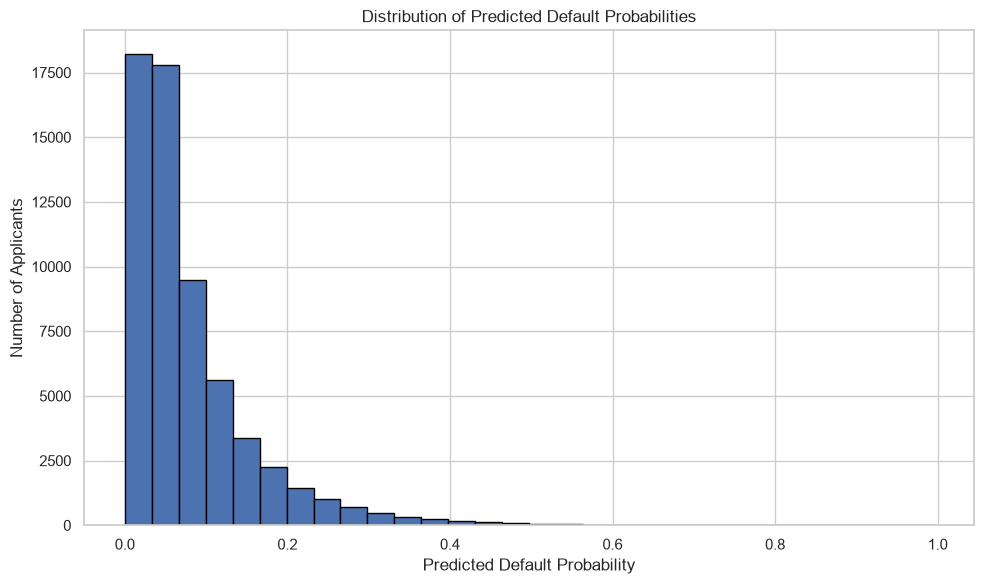

In [28]:
plt.figure(figsize=(10,6))

plt.hist(

    prediction_df["Default Probability"],

    bins=30,

    edgecolor="black"

)

plt.xlabel("Predicted Default Probability")

plt.ylabel("Number of Applicants")

plt.title("Distribution of Predicted Default Probabilities")

plt.tight_layout()

plt.show()

# Generate Standardized Credit Risk Scores

The predicted probability of default is transformed into a standardized credit risk score ranging from **300 to 900**.

Applicants with lower default probabilities receive higher credit scores, indicating lower credit risk. Conversely, applicants with higher default probabilities receive lower credit scores.

The transformation is defined as:

\[
\text{Credit Score} = 900 - (Probability \times 600)
\]

This produces scores within the conventional credit scoring range used in many financial institutions.

In [29]:
# ============================================================
# Generate Credit Scores
# ============================================================

prediction_df["Credit Score"] = (
    900 - prediction_df["Default Probability"] * 600
).round().astype(int)

prediction_df.head()

,SK_ID_CURR,Actual Default,Predicted Default,Default Probability,Credit Score
0,396899,0,0,0.028908,883
1,322041,0,0,0.043369,874
2,220127,0,0,0.212473,773
3,251531,0,0,0.172851,796
4,345558,0,0,0.145149,813


# Summary Statistics of Credit Scores

The descriptive statistics below provide an overview of the generated credit scores across the applicant population.

In [30]:
prediction_df["Credit Score"].describe()

count    61503.000000
mean       851.716420
std         47.439109
min        303.000000
25%        839.000000
50%        868.000000
75%        882.000000
max        900.000000
Name: Credit Score, dtype: float64

# Assign Credit Risk Bands

To improve interpretability, applicants are categorized into five credit risk bands based on their credit scores.

| Credit Score | Risk Band |
|--------------|-----------|
| 800–900 | Excellent |
| 700–799 | Good |
| 600–699 | Fair |
| 500–599 | Poor |
| 300–499 | High Risk |

These bands simplify lending decisions by grouping applicants according to their estimated creditworthiness.

In [31]:
# ============================================================
# Risk Band Classification
# ============================================================

def assign_risk_band(score):

    if score >= 800:
        return "Excellent"

    elif score >= 700:
        return "Good"

    elif score >= 600:
        return "Fair"

    elif score >= 500:
        return "Poor"

    else:
        return "High Risk"


prediction_df["Risk Band"] = prediction_df["Credit Score"].apply(assign_risk_band)

prediction_df.head()

,SK_ID_CURR,Actual Default,Predicted Default,Default Probability,Credit Score,Risk Band
0,396899,0,0,0.028908,883,Excellent
1,322041,0,0,0.043369,874,Excellent
2,220127,0,0,0.212473,773,Good
3,251531,0,0,0.172851,796,Good
4,345558,0,0,0.145149,813,Excellent


# Distribution of Credit Scores

The histogram below illustrates the distribution of generated credit scores across the testing dataset.

This visualization provides insight into the overall credit quality of the applicant population.

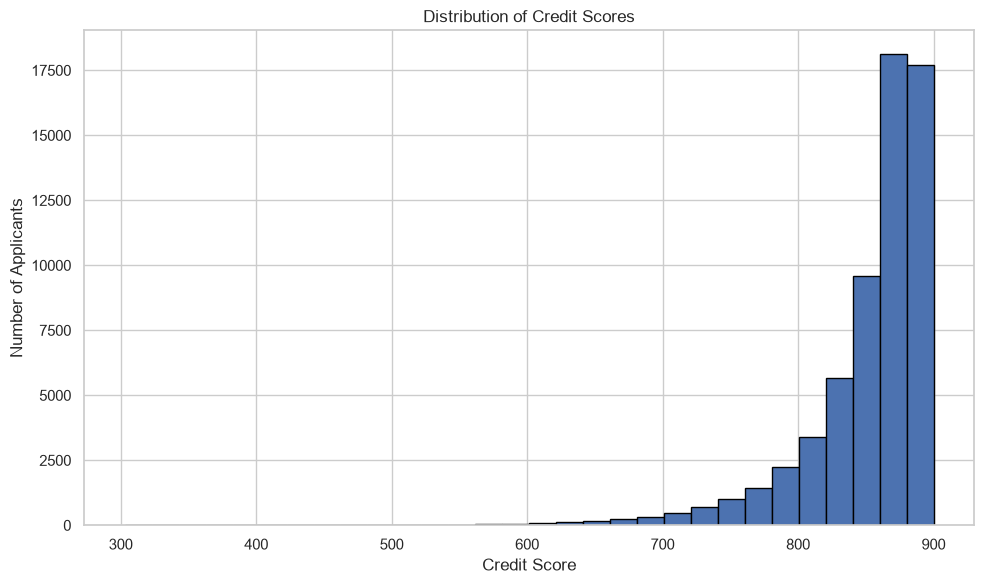

In [32]:
plt.figure(figsize=(10,6))

plt.hist(
    prediction_df["Credit Score"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Credit Scores")

plt.xlabel("Credit Score")

plt.ylabel("Number of Applicants")

plt.tight_layout()

plt.show()

# Distribution of Credit Risk Bands

The following chart summarizes the number of applicants assigned to each risk category.

This representation enables lenders to quickly understand the distribution of applicants across different levels of credit risk.

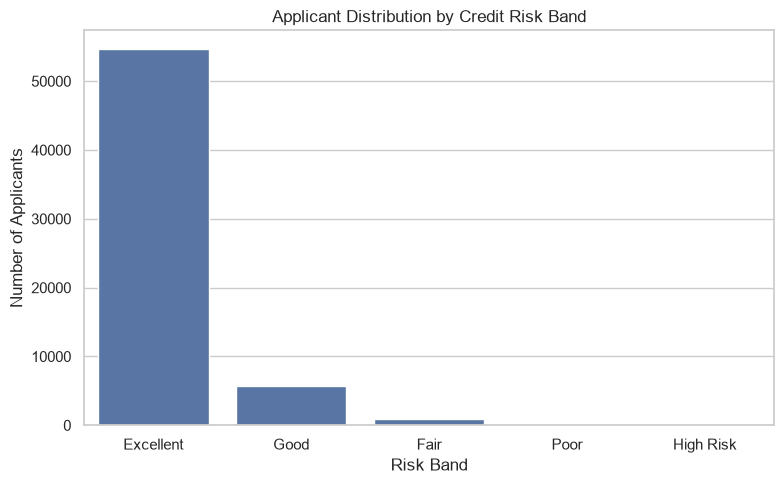

In [33]:
plt.figure(figsize=(8,5))

order = [
    "Excellent",
    "Good",
    "Fair",
    "Poor",
    "High Risk"
]

sns.countplot(
    data=prediction_df,
    x="Risk Band",
    order=order
)

plt.title("Applicant Distribution by Credit Risk Band")

plt.xlabel("Risk Band")

plt.ylabel("Number of Applicants")

plt.tight_layout()

plt.show()

# Summary of Credit Risk Bands

The table below presents the number and percentage of applicants assigned to each credit risk category.

In [34]:
risk_summary = (
    prediction_df["Risk Band"]
    .value_counts()
    .reindex(order)
    .reset_index()
)

risk_summary.columns = ["Risk Band", "Applicants"]

risk_summary["Percentage (%)"] = (
    risk_summary["Applicants"] /
    len(prediction_df) * 100
).round(2)

risk_summary

,Risk Band,Applicants,Percentage (%)
0,Excellent,54636,88.83
1,Good,5719,9.30
2,Fair,969,1.58
3,Poor,163,0.27
4,High Risk,16,0.03


# Save Final Credit Risk Scores

The applicant-level predictions, standardized credit scores, and assigned risk bands are saved for use in the subsequent Fairness Analysis notebook.

This dataset represents the final output of the credit risk scoring model and serves as the foundation for evaluating model fairness and stability across demographic groups.

In [35]:
# ============================================================
# Save Credit Risk Scores
# ============================================================

RESULT_DIR.mkdir(parents=True, exist_ok=True)

prediction_df.to_csv(
    RESULT_DIR / "credit_risk_scores.csv",
    index=False
)

print("Credit risk scores saved successfully.")
print(f"Location: {RESULT_DIR / 'credit_risk_scores.csv'}")

Credit risk scores saved successfully.
Location: ..\results\credit_risk_scores.csv
